
# Topic 3: Covariance and Portfolio Selection

**Core Question:** How can we construct a portfolio that achieves a target expected return with minimum risk?

**Learning Roadmap**

1. **Covariance:** Understand individual risk and how assets move together.
2. **Multivariate Normals:** Model correlated random variables.
3. **Cholesky Decomposition:** Transform independent normals into correlated normals.
4. **Markowitz Model:** Express portfolio return and risk mathematically.
5. **Portfolio Optimisation:** Derive optimal weights using calculus and Lagrange multipliers.
6. **Numerical Methods:** Estimate parameters from historical data and solve using NumPy and CVXOPT.
7. **Efficient Frontier:** Identify optimal risk–return combinations.

**Core Connections**

$$
\Sigma=\operatorname{Cov}(Y)
\quad\longrightarrow\quad
Y=LX+\mu,\;\Sigma=LL^\top
$$

$$
E[r_p]=w^\top\mu,\qquad
\operatorname{Var}(r_p)=w^\top\Sigma w
$$

$$
\boxed{
\min_w w^\top\Sigma w
\quad
\text{subject to }
\mathbf1^\top w=1,\;
\mu^\top w=R
}
$$

> **Notes：** 本周从 Covariance 出发，学习如何描述并模拟相关随机变量，随后将 Expected Returns 和 Covariance Matrix 应用于 Markowitz Portfolio Selection。最终目标是求出最优权重，并理解 Efficient Frontier。


In [2]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Covariance and Multivariate Normal Distributions

For a random vector $Y=(Y_1,\ldots,Y_n)^\top$:

$$
\mu=E[Y],\qquad
\Sigma=\operatorname{Cov}(Y)
=E[(Y-\mu)(Y-\mu)^\top]
$$

- **Variance:** $\Sigma_{ii}=\operatorname{Var}(Y_i)$.
- **Covariance:** $\Sigma_{ij}=\operatorname{Cov}(Y_i,Y_j)$.
- **Correlation:** $\rho_{ij}=\Sigma_{ij}/(\sigma_i\sigma_j)$.
- **Positive Definite:** $v^\top\Sigma v>0$ for all nonzero $v$.

**Linear Combinations**

$$
E[v^\top Y]=v^\top\mu
$$

$$
\boxed{\operatorname{Var}(v^\top Y)=v^\top\Sigma v}
$$

This identity is fundamental to portfolio risk.

**Constructing Multivariate Normals**

Let $X\sim N_n(0,I_n)$ have independent standard normal components.

$$
\boxed{Y=HX+\mu}
$$

Then:

$$
E[Y]=HE[X]+\mu=\mu
$$

$$
\begin{aligned}
\operatorname{Cov}(Y)
&=E[(HX)(HX)^\top]\\
&=HE[XX^\top]H^\top\\
&=\boxed{HH^\top}
\end{aligned}
$$

**Example**

$$
H=\begin{pmatrix}2&0\\1&1\end{pmatrix}
\quad\Rightarrow\quad
\Sigma=HH^\top=
\begin{pmatrix}4&2\\2&2\end{pmatrix}
$$

> **Notes：** 独立的 Standard Normals 经矩阵 $H$ 变换后，可以产生相关性。需要注意：Independence implies zero covariance，但反过来通常不成立；对于 Jointly Normal Variables，零协方差才意味着独立。


[[2. 0.]
 [1. 1.]]
(2, 1000)


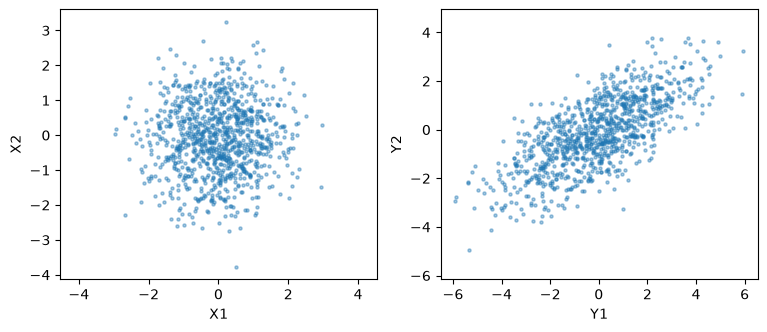

In [3]:
rng = np.random.default_rng(37)
X = rng.standard_normal((2, 1000))
H = np.array([[2., 0.], [1., 1.]])
Y = H @ X
print(H)
print(Y.shape)

fig, axes = plt.subplots(1, 2, figsize = (9, 3.5))
for ax, draws, label in zip(axes, [X, Y], ["X", "Y"]):
    ax.scatter(draws[0], draws[1],s = 5, alpha = 0.4)
    ax.set(xlabel = label + "1", ylabel = label + "2")
    ax.set_aspect("equal", adjustable = "datalim")

plt.show()


### PDF, Contours and Simulated Samples

For a nondegenerate multivariate normal distribution:

$$
f_Y(y)=
\frac{
\exp\left[-\frac12(y-\mu)^\top\Sigma^{-1}(y-\mu)\right]
}{
(2\pi)^{n/2}\sqrt{\det\Sigma}
}
$$

- **PDF:** Describes probability density, not the probability of an exact point.
- **Contour:** Connects points with equal density.
- **Scatter Plot:** Displays randomly generated observations.
- **Independent Standard Normals:** Circular contours.
- **Correlated Normals:** Generally tilted elliptical contours.

> **Notes：** 本节 PDF 的推导不要求考试掌握。重点是理解分布来自 Standard Multivariate Normal 的 Transformation，以及 Scatter Plot 和 Contour Plot 分别表示什么。


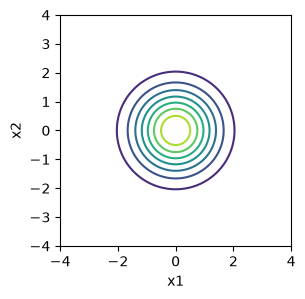

In [4]:
grid = np.linspace(-4, 4, 121)
x1, x2 = np.meshgrid(grid, grid)
f = np.exp(-(x1**2 + x2**2) / 2) / (2 * np.pi)
fig, ax = plt.subplots(figsize = (3.5, 3))
ax.contour(x1, x2, f)
ax.set(xlabel= 'x1', ylabel= 'x2', aspect= 'equal')
plt.show()



## 2. Cholesky Decomposition and Simulation

**Definition**

For symmetric positive-definite $\Sigma$, there exists a unique lower-triangular matrix $L$ with positive diagonal such that:

$$
\boxed{\Sigma=LL^\top}
$$

**2×2 Derivation**

$$
\Sigma=
\begin{pmatrix}a&c\\c&b\end{pmatrix},
\qquad
L=
\begin{pmatrix}l_{11}&0\\l_{21}&l_{22}\end{pmatrix}
$$

Matching the entries of $LL^\top$:

$$
l_{11}^2=a,\quad
l_{11}l_{21}=c,\quad
l_{21}^2+l_{22}^2=b
$$

Therefore:

$$
\boxed{
l_{11}=\sqrt a,\quad
l_{21}=\frac{c}{\sqrt a},\quad
l_{22}=\sqrt{b-\frac{c^2}{a}}
}
$$

**Example**

$$
\Sigma=
\begin{pmatrix}4&2\\2&2\end{pmatrix}
\quad\Rightarrow\quad
L=
\begin{pmatrix}2&0\\1&1\end{pmatrix}
$$

**Simulation**

Given $X\sim N_n(0,I_n)$:

$$
\boxed{Y=LX+\mu\sim N_n(\mu,\Sigma)}
$$

Because:

$$
E[Y]=\mu,\qquad
\operatorname{Cov}(Y)=LL^\top=\Sigma
$$

**Python Interpretation**

- `np.linalg.cholesky(sigma)`: Calculate $L$.
- `L @ X`: Introduce the required covariance.
- `mu[:, None]`: Broadcast the mean across observations.
- `Y.mean(axis=1)`: Estimate the simulated mean.
- `np.cov(Y)`: Estimate the simulated covariance.

> **Notes：** 考试需要能够手算 Cholesky（包括 3×3）并用 Python 模拟多元正态分布。$L@L.T$ 是代数验证，而 Sample Mean / Covariance 是统计验证。Cholesky 存在性的归纳法证明属于 Optional。


In [5]:
sigma = np.array([[4., 2.], [2., 2.]])
mu = np.array([1., -1.])
L = np.linalg.cholesky(sigma)
print(L @ L.T)

X = rng.standard_normal((2, 10000))
Y = L @ X + mu[:, None]
print(Y.mean(axis=1))
print(np.cov(Y))

[[4. 2.]
 [2. 2.]]
[ 0.97898432 -1.00998068]
[[4.06069766 2.01751163]
 [2.01751163 2.01731052]]



## 3. Markowitz Portfolio Selection

### Portfolio Return and Risk

Let $w_i$ be the portfolio weight of asset $i$, and $r_i$ its simple return.

$$
r_p=\sum_{i=1}^n w_ir_i=w^\top r
$$

**Expected Return**

$$
\boxed{E[r_p]=w^\top\mu}
$$

**Portfolio Variance**

$$
\boxed{\sigma_p^2=w^\top\Sigma w}
$$

For two assets:

$$
\sigma_p^2=
w_1^2\sigma_1^2+w_2^2\sigma_2^2+
2w_1w_2\rho\sigma_1\sigma_2
$$

### The Markowitz Optimisation Problem

$$
\boxed{\min_w w^\top\Sigma w}
$$

Subject to:

$$
\boxed{
\mathbf1^\top w=1,\qquad
\mu^\top w=R
}
$$

- **Objective:** Minimise portfolio risk.
- **Budget Constraint:** Weights sum to 1.
- **Target-Return Constraint:** Expected return equals $R$.

**Assumptions and Limitations**

The basic model allows short-selling, assumes positive-definite covariance and at least two distinct expected returns. It treats $\mu$ and $\Sigma$ as known inputs during optimisation.

Historical estimates may be inaccurate; correlations may change. Trading costs, taxes and short-selling restrictions are omitted. Variance also penalises upside and downside fluctuations equally.

> **Notes：** Markowitz 的创新在于从单个资产转向整个 Portfolio。真正影响组合风险的是 Variance 和 Covariance 的共同作用。以上均值和方差公式并不要求 Returns 服从正态分布。

---

### 3.1 Two-Asset Portfolio

**Target Return Problem**

$$
w_1+w_2=1,\qquad
\mu_1w_1+\mu_2w_2=R
$$

Solving these constraints:

$$
\boxed{
w_1=\frac{R-\mu_2}{\mu_1-\mu_2},
\qquad
w_2=\frac{\mu_1-R}{\mu_1-\mu_2}
}
$$

Two independent constraints determine both weights, leaving no freedom to optimise.

**Global Minimum-Variance Portfolio**

Without fixing target return, substitute $w_2=1-w_1$:

$$
\sigma_p^2=
\sigma_1^2w_1^2+
2\rho\sigma_1\sigma_2w_1(1-w_1)+
\sigma_2^2(1-w_1)^2
$$

Differentiate:

$$
\frac{d\sigma_p^2}{dw_1}
=
2\sigma_1^2w_1+
2\rho\sigma_1\sigma_2(1-2w_1)
-2\sigma_2^2(1-w_1)
$$

Set the derivative to zero:

$$
\boxed{
w_1^*=
\frac{\sigma_2^2-\rho\sigma_1\sigma_2}
{\sigma_1^2+\sigma_2^2-2\rho\sigma_1\sigma_2}
}
$$

$$
w_2^*=1-w_1^*
$$

> **Notes：** 要区分 Target Return Portfolio 和 Global Minimum-Variance Portfolio。前者在两资产情况下可直接解约束；后者只保留预算约束，需要对 Variance 求导。

### 3.2 Three-Asset Portfolio

Consider three uncorrelated assets:

$$
\mu=(0.04,0.08,0.12)^\top
$$

$$
\Sigma=\operatorname{diag}(0.01,0.04,0.01)
$$

With $R=0.08$, the constraints are:

$$
w_1+w_2+w_3=1
$$

$$
0.04w_1+0.08w_2+0.12w_3=0.08
$$

Subtracting 0.08 times the first equation:

$$
w_1=w_3=t,\qquad w_2=1-2t
$$

Portfolio variance becomes:

$$
\begin{aligned}
v(t)
&=0.01t^2+0.04(1-2t)^2+0.01t^2\\
&=0.18t^2-0.16t+0.04
\end{aligned}
$$

First-order condition:

$$
v'(t)=0.36t-0.16=0
$$

$$
\boxed{t=\frac49}
$$

Since $v''(t)>0$, this is the minimum:

$$
\boxed{
w^*=\left(\frac49,\frac19,\frac49\right)^\top,
\qquad
\sigma_p\approx6.67\%
}
$$

> **Notes：** 三资产有三个未知权重、两个约束，剩下一个自由变量。先用 Constraints 消去两个变量，再通过 Calculus 求最小方差。

### 3.3 General n-Asset Problem: Lagrange Multipliers

For $n$ assets, two independent constraints leave $n-2$ degrees of freedom.

**Step 1: Lagrangian**

$$
\mathcal L(w,\lambda_1,\lambda_2)
=
\frac12w^\top\Sigma w+
\lambda_1(1-\mathbf1^\top w)+
\lambda_2(R-\mu^\top w)
$$

**Step 2: First-Order Conditions**

$$
\nabla_w\mathcal L
=\Sigma w-\lambda_1\mathbf1-\lambda_2\mu=0
$$

Together with:

$$
\mathbf1^\top w=1,\qquad \mu^\top w=R
$$

Hence:

$$
\boxed{
w=\lambda_1\Sigma^{-1}\mathbf1+
\lambda_2\Sigma^{-1}\mu
}
$$

**Step 3: Substitute into the Constraints**

$$
\lambda_1\mathbf1^\top\Sigma^{-1}\mathbf1+
\lambda_2\mathbf1^\top\Sigma^{-1}\mu=1
$$

$$
\lambda_1\mu^\top\Sigma^{-1}\mathbf1+
\lambda_2\mu^\top\Sigma^{-1}\mu=R
$$

To simplify these expressions, define:

$$
A=\mathbf1^\top\Sigma^{-1}\mathbf1,\quad
B=\mu^\top\Sigma^{-1}\mathbf1
$$

$$
C=\mu^\top\Sigma^{-1}\mu,\quad
D=AC-B^2
$$

The equations become:

$$
\begin{cases}
A\lambda_1+B\lambda_2=1\\
B\lambda_1+C\lambda_2=R
\end{cases}
$$

**Step 4: Solve for the Multipliers**

$$
\boxed{
\lambda_1=\frac{C-BR}{D},
\qquad
\lambda_2=\frac{AR-B}{D}
}
$$

**Step 5: Optimal Portfolio Weights**

$$
\boxed{
w(R)=
\frac{C-BR}{D}\Sigma^{-1}\mathbf1+
\frac{AR-B}{D}\Sigma^{-1}\mu
}
$$

**Step 6: Minimum Variance**

From $\Sigma w=\lambda_1\mathbf1+\lambda_2\mu$:

$$
\begin{aligned}
\sigma_{\min}^2(R)
&=w^\top\Sigma w\\
&=\lambda_1w^\top\mathbf1+
\lambda_2w^\top\mu\\
&=\lambda_1+\lambda_2R
\end{aligned}
$$

Therefore:

$$
\boxed{
\sigma_{\min}^2(R)=
\frac{AR^2-2BR+C}{D}
}
$$

Positive definiteness of $\Sigma$ guarantees a unique minimum.

> **Notes：** 重点掌握完整推导顺序：建立 Lagrangian → 对权重与乘子求偏导 → 代入两个 Constraints → 定义 A、B、C、D 简化方程 → 求解 Multipliers → 得到最优权重和 Minimum Variance。不要直接死记 A、B、C、D。



## 4. Estimating Portfolio Inputs from Historical Data

**Workflow**

$$
\text{Prices}\rightarrow\text{Returns}
\rightarrow\hat\mu,\hat\Sigma
$$

For stock $i$:

$$
r_{t,i}=\frac{P_{t,i}-P_{t-1,i}}{P_{t-1,i}}
$$

**Data Structure**

| Variable | Shape | Meaning |
|---|---|---|
| `price_history` | `(734, 75)` | Prices: dates × stocks |
| `return_history` | `(733, 75)` | Weekly returns |
| `mu` | `(75,)` | Estimated expected returns |
| `sigma` | `(75, 75)` | Estimated covariance matrix |

**Key Operations**

- `.iloc[2:, 1::3]`: Skip two header rows and select every third column, starting from index 1.
- `mean(axis=0)`: Average down rows, obtaining one mean per stock.
- `np.cov(..., rowvar=False)`: Treat columns as variables.
- `np.sqrt(np.diag(sigma))`: Obtain each stock's standard deviation.

> **Notes：** 股票收益率必须按日期正确对齐。这里计算的是 Weekly Returns，因此 $\mu$ 和 $\Sigma$ 分别是周收益率均值与周协方差矩阵。Section 3 的模拟数据按行放变量，而这里按列放股票，所以计算 Covariance 时需要 `rowvar=False`。


In [6]:
import pandas as pd 

excel_data = pd.read_excel("ukx.xlsx", header=None) 
price_history = excel_data.iloc[2:, 1::3].to_numpy(dtype=float) 
print(excel_data.shape, price_history.shape) 
# (736, 224), (734, 75)

FileNotFoundError: [Errno 2] No such file or directory: 'ukx.xlsx'

In [5]:
start_prices = price_history[:-1, :] 
end_prices = price_history[1:, :] 
return_history = (end_prices- start_prices) / start_prices 
mu = return_history.mean(axis=0) 
sigma = np.cov(return_history, rowvar=False)

print(mu.shape)
print(sigma.shape)

(75,)
(75, 75)


In [6]:
def plot_stock_points(sigma, mu): 
    ax = plt.gca() 
    ax.scatter(np.sqrt(np.diag(sigma)), mu, s=15) 
    ax.set_xlabel("Weekly standard deviation") 
    ax.set_ylabel("Expected weekly return")


## 5. Analytic Portfolio Solution

Given estimated $\mu$, $\Sigma$ and target weekly return $R=0.003$, use the formula derived from Lagrange multipliers.

Instead of explicitly computing $\Sigma^{-1}$, solve:

$$
\boxed{
\Sigma u=\mathbf1,\qquad
\Sigma v=\mu
}
$$

Then:

$$
A=\mathbf1^\top u,\qquad
B=\mu^\top u,\qquad
C=\mu^\top v,\qquad
D=AC-B^2
$$

**Optimal Weights**

$$
\boxed{
w(R)=\frac{(C-BR)u+(AR-B)v}{D}
}
$$

**Python Logic**

- `np.column_stack([ones, mu])`: Combine two right-hand sides.
- `np.linalg.solve()`: Solve both linear systems without explicitly forming the inverse.
- `ones @ u`, `mu @ u`, `mu @ v`: Calculate A, B, C.
- `w.sum()`: Check the budget constraint.
- `mu @ w`: Check the target-return constraint.

> **Notes：** 解析解是 Section 5 数学推导的直接实现。`np.linalg.solve()` 通常比显式求逆更高效且数值稳定。最终应验证 $\sum_iw_i\approx1$ 和 $\mu^\top w\approx0.003$。


In [7]:
R = 0.003 
ones = np.ones(len(mu)) 
uv = np.linalg.solve(sigma, np.column_stack([ones, mu])) 
u, v = uv[:, 0], uv[:, 1]            # sigmaˆ-1 ones, sigmaˆ-1 mu
A, B, C = ones @ u, mu @ u, mu @ v 
D = A * C- B**2 
w = ((C- B * R) * u + (A * R- B) * v) / D 
print(w.sum(), mu @ w)              # Approximately 1 and 0.003

1.0 0.003


[[2. 0.]
 [1. 1.]]
(2, 1000)


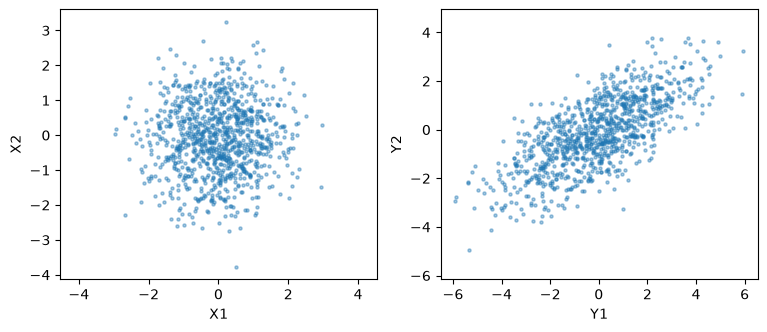

In [ ]:
rng = np.random.default_rng(37)
X = rng.standard_normal((2, 1000))
H = np.array([[2., 0.], [1., 1.]])
Y = H @ X
print(H)
print(Y.shape)

fig, axes = plt.subplots(1, 2, figsize = (9, 3.5))
for ax, draws, label in zip(axes, [X, Y], ["X", "Y"]):
    ax.scatter(draws[0], draws[1],s = 5, alpha = 0.4)
    ax.set(xlabel = label + "1", ylabel = label + "2")
    ax.set_aspect("equal", adjustable = "datalim")

plt.show()

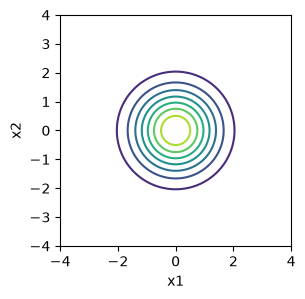

In [ ]:
grid = np.linspace(-4, 4, 121)
x1, x2 = np.meshgrid(grid, grid)
f = np.exp(-(x1**2 + x2**2) / 2) / (2 * np.pi)
fig, ax = plt.subplots(figsize = (3.5, 3))
ax.contour(x1, x2, f)
ax.set(xlabel= 'x1', ylabel= 'x2', aspect= 'equal')
plt.show()


In [ ]:
sigma = np.array([[4., 2.], [2., 2.]])
mu = np.array([1., -1.])
L = np.linalg.cholesky(sigma)
print(L @ L.T)

X = rng.standard_normal((2, 10000))
Y = L @ X + mu[:, None]
print(Y.mean(axis=1))
print(np.cov(Y))

[[4. 2.]
 [2. 2.]]
[ 0.97898432 -1.00998068]
[[4.06069766 2.01751163]
 [2.01751163 2.01731052]]


In [ ]:
import pandas as pd 

excel_data = pd.read_excel("ukx.xlsx", header=None) 
price_history = excel_data.iloc[2:, 1::3].to_numpy(dtype=float) 
print(excel_data.shape, price_history.shape) 
# (736, 224), (734, 75)

(736, 224) (734, 75)


In [ ]:
start_prices = price_history[:-1, :] 
end_prices = price_history[1:, :] 
return_history = (end_prices- start_prices) / start_prices 
mu = return_history.mean(axis=0) 
sigma = np.cov(return_history, rowvar=False)

print(mu.shape)
print(sigma.shape)

(75,)
(75, 75)


In [ ]:
def plot_stock_points(sigma, mu): 
    ax = plt.gca() 
    ax.scatter(np.sqrt(np.diag(sigma)), mu, s=15) 
    ax.set_xlabel("Weekly standard deviation") 
    ax.set_ylabel("Expected weekly return")

In [ ]:
R = 0.003 
ones = np.ones(len(mu)) 
uv = np.linalg.solve(sigma, np.column_stack([ones, mu])) 
u, v = uv[:, 0], uv[:, 1]            # sigmaˆ-1 ones, sigmaˆ-1 mu
A, B, C = ones @ u, mu @ u, mu @ v 
D = A * C- B**2 
w = ((C- B * R) * u + (A * R- B) * v) / D 
print(w.sum(), mu @ w)              # Approximately 1 and 0.003

1.0 0.003



## 6. Quadratic Programming with CVXOPT

**Standard QP Problem**

$$
\min_x\frac12x^\top Px+q^\top x
$$

Subject to:

$$
Gx\le h,\qquad Ax=b
$$

**Markowitz Formulation**

$$
\min_w w^\top\Sigma w
$$

Subject to:

$$
\mathbf1^\top w=1,\qquad\mu^\top w=R
$$

Match the parameters:

$$
x=w,\quad P=2\Sigma,\quad q=0
$$

$$
A=
\begin{pmatrix}\mathbf1^\top\\\mu^\top\end{pmatrix},
\qquad
b=\begin{pmatrix}1\\R\end{pmatrix}
$$

No inequality constraints are imposed in this example.

**Python Logic**

- `np.vstack()`: Construct the equality-constraint matrix.
- `matrix(..., tc="d")`: Create CVXOPT double-precision matrices.
- `solvers.qp()`: Solve the quadratic programme.
- `res["status"]`: Check whether the solver reached `"optimal"`.
- `res["x"]`: Extract optimal weights.
- `w @ sigma @ w`: Calculate portfolio variance.

> **Notes：** CVXOPT 与上一节的 Analytic Method 解决的是同一个问题。设置 $P=2\Sigma$ 是为了抵消 QP Objective 中的 $\frac12$。数值求解器的优势是以后可以方便地加入 No-Short-Selling 等线性约束。


In [ ]:
from cvxopt import matrix, solvers

def solve_markowiz(sigma, mu, R):
    # Assumes SPD sigma and at least two different expected returns.
    sigma = np.asarray(sigma, dtype=float)
    mu = np.asarray(mu, dtype=float).reshape(-1)
    n = mu.size

    P = matrix(2 * sigma, tc = 'd')
    q = matrix(np.zeros(n), tc = 'd')
    A = matrix(np.vstack([np.ones(n), mu]), tc = 'd')
    b = matrix(np.array([1., R]), tc = 'd')

    res = solvers.qp(P, q, A=A, b=b, options={"show_progress": True})
    if res["status"] != "optimal":
        raise RuntimeError("Solver status: " + res["status"])
    w = np.asarray(res["x"]).reshape(-1)
    variance = float(w @sigma @w)
    return {"weights": w, "sd": np.sqrt(variance) }



## 7. Minimum-Variance Curve and Efficient Frontier

For each target expected return $R$, the optimal portfolio has:

$$
E[r_p]=R,\qquad
\sigma_p=\sigma_{\min}(R)
$$

As $R$ varies, these portfolios form the **Minimum-Variance Curve**.

$$
\boxed{
\sigma_{\min}^2(R)=\frac{AR^2-2BR+C}{D}
}
$$

Completing the square:

$$
\sigma_{\min}^2(R)
=
\frac AD\left(R-\frac BA\right)^2+\frac1A
$$

**Global Minimum-Variance Portfolio (GMVP)**

$$
\boxed{
R_{\mathrm{GMV}}=\frac BA,\qquad
\sigma_{\mathrm{GMV}}^2=\frac1A
}
$$

The GMVP is the leftmost point of the curve.

**Efficient Frontier**

- Upper branch + GMVP: Efficient portfolios.
- Lower branch: Dominated portfolios.
- A dominated portfolio offers an inferior risk–return trade-off compared with another available portfolio.

**Plot Interpretation**

- X-axis: Portfolio Standard Deviation.
- Y-axis: Expected Portfolio Return.
- Scatter points: Individual stocks.
- Curve: Minimum-variance portfolios for different target returns.

> **Notes：** 你的 Python 图画的是完整的 Minimum-Variance Curve，而不仅仅是 Efficient Frontier。需要能够解释为什么下半支被支配，以及为什么不同风险偏好的投资者会选择有效前沿上的不同点。


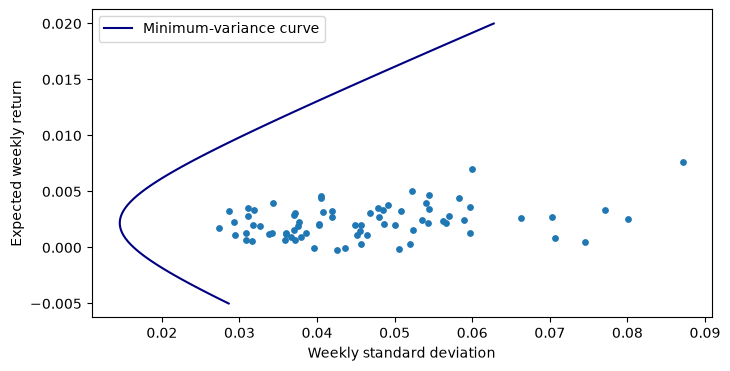

In [ ]:
returns = np.linspace(-0.005, 0.02, 100)
min_sds = np.array([
    solve_markowiz(sigma, mu, R)["sd"] for R in returns
])
fig, ax = plt.subplots(figsize = (8,4))
ax.plot(min_sds, returns, label = "Minimum-variance curve", c='navy')
plot_stock_points(sigma, mu)
ax.legend()
plt.show()

In [8]:
from cvxopt import matrix, solvers

def solve_markowiz(sigma, mu, R):
    # Assumes SPD sigma and at least two different expected returns.
    sigma = np.asarray(sigma, dtype=float)
    mu = np.asarray(mu, dtype=float).reshape(-1)
    n = mu.size

    P = matrix(2 * sigma, tc = 'd')
    q = matrix(np.zeros(n), tc = 'd')
    A = matrix(np.vstack([np.ones(n), mu]), tc = 'd')
    b = matrix(np.array([1., R]), tc = 'd')

    res = solvers.qp(P, q, A=A, b=b, options={"show_progress": True})
    if res["status"] != "optimal":
        raise RuntimeError("Solver status: " + res["status"])
    w = np.asarray(res["x"]).reshape(-1)
    variance = float(w @sigma @w)
    return {"weights": w, "sd": np.sqrt(variance) }


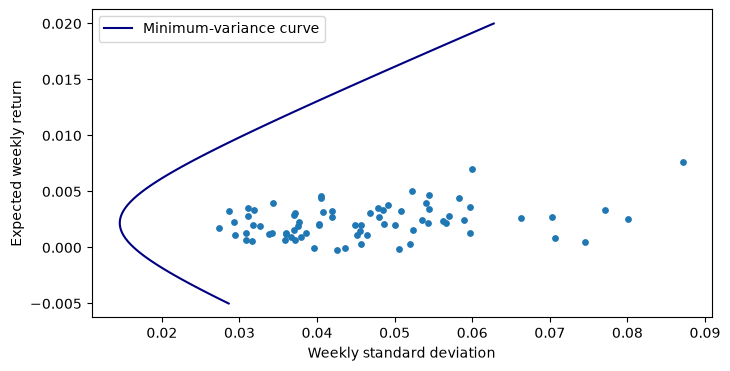

In [9]:
returns = np.linspace(-0.005, 0.02, 100)
min_sds = np.array([
    solve_markowiz(sigma, mu, R)["sd"] for R in returns
])
fig, ax = plt.subplots(figsize = (8,4))
ax.plot(min_sds, returns, label = "Minimum-variance curve", c='navy')
plot_stock_points(sigma, mu)
ax.legend()
plt.show()